In [21]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as plx
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Styling visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [22]:
patients = pd.read_csv(r'data\patients.csv')
doctors = pd.read_csv(r'data\doctors.csv')
appointments = pd.read_csv(r'data\appointments.csv')
treatments = pd.read_csv(r'data\treatments.csv')
billing = pd.read_csv(r'data\billing.csv')

--- PATIENTS: INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   patient_id          50 non-null     object
 1   first_name          50 non-null     object
 2   last_name           50 non-null     object
 3   gender              50 non-null     object
 4   date_of_birth       50 non-null     object
 5   contact_number      50 non-null     int64 
 6   address             50 non-null     object
 7   registration_date   50 non-null     object
 8   insurance_provider  50 non-null     object
 9   insurance_number    50 non-null     object
 10  email               50 non-null     object
dtypes: int64(1), object(10)
memory usage: 4.4+ KB
None

--- PATIENTS: SHAPE ---
(50, 11)


C:\Users\salma\AppData\Local\Temp\ipykernel_10576\2181421298.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=patients, x='gender', palette='Set2')


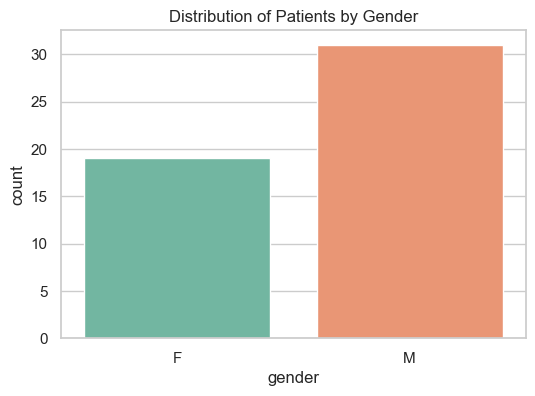

In [23]:
print("--- PATIENTS: INFO ---")
print(patients.info())

print("\n--- PATIENTS: SHAPE ---")
print(patients.shape)

# Visualizations & Question Analysis
plt.figure(figsize=(6, 4))
sns.countplot(data=patients, x='gender', palette='Set2')
plt.title('Distribution of Patients by Gender')
plt.show()

In [24]:
# Data Cleaning: Handle missing values
patients.fillna({'contact_number': 'Unknown', 'email': 'Unknown', 'address': 'Unknown', 
                 'insurance_provider': 'None', 'insurance_number': 'None'}, inplace=True)

# Feature Engineering 1: Convert date_of_birth to datetime and calculate 'age'
patients['date_of_birth'] = pd.to_datetime(patients['date_of_birth'])
current_year = pd.Timestamp.now().year
patients['age'] = current_year - patients['date_of_birth'].dt.year

# Feature Engineering 2: Create 'full_name'
patients['full_name'] = patients['first_name'].str.strip() + ' ' + patients['last_name'].str.strip()

print("Patients Cleaning & Feature Engineering Complete. Sample:")
display(patients[['patient_id', 'full_name', 'age', 'gender', 'insurance_provider']].head())

Patients Cleaning & Feature Engineering Complete. Sample:


,patient_id,full_name,age,gender,insurance_provider
0,P001,David Williams,71,F,WellnessCorp
1,P002,Emily Smith,42,F,PulseSecure
2,P003,Laura Jones,49,M,PulseSecure
3,P004,Michael Johnson,45,F,HealthIndia
4,P005,David Wilson,66,M,MedCare Plus


--- DOCTORS: INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   doctor_id         10 non-null     object
 1   first_name        10 non-null     object
 2   last_name         10 non-null     object
 3   specialization    10 non-null     object
 4   phone_number      10 non-null     int64 
 5   years_experience  10 non-null     int64 
 6   hospital_branch   10 non-null     object
 7   email             10 non-null     object
dtypes: int64(2), object(6)
memory usage: 772.0+ bytes
None

--- DOCTORS: SHAPE ---
(10, 8)


C:\Users\salma\AppData\Local\Temp\ipykernel_10576\2125715580.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=doctors, y='specialization', order=doctors['specialization'].value_counts().index, palette='Blues_d')


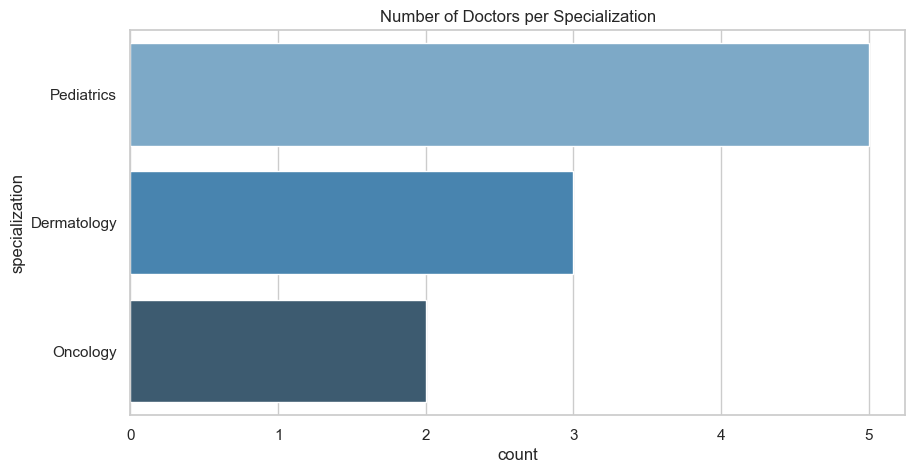

In [25]:
print("--- DOCTORS: INFO ---")
print(doctors.info())

print("\n--- DOCTORS: SHAPE ---")
print(doctors.shape)

# Visualization: Doctors per Specialization
plt.figure(figsize=(10, 5))
sns.countplot(data=doctors, y='specialization', order=doctors['specialization'].value_counts().index, palette='Blues_d')
plt.title('Number of Doctors per Specialization')
plt.show()

In [26]:
# Data Cleaning
doctors.fillna({'phone_number': 'Unknown', 'email': 'Unknown'}, inplace=True)

# Feature Engineering: Create professional full name
doctors['full_name'] = 'Dr. ' + doctors['first_name'].str.strip() + ' ' + doctors['last_name'].str.strip()

print("Doctors Cleaning & Feature Engineering Complete. Sample:")
display(doctors[['doctor_id', 'full_name', 'specialization', 'hospital_branch', 'years_experience']].head())

Doctors Cleaning & Feature Engineering Complete. Sample:


,doctor_id,full_name,specialization,hospital_branch,years_experience
0,D001,Dr. David Taylor,Dermatology,Westside Clinic,17
1,D002,Dr. Jane Davis,Pediatrics,Eastside Clinic,24
2,D003,Dr. Jane Smith,Pediatrics,Eastside Clinic,19
3,D004,Dr. David Jones,Pediatrics,Central Hospital,28
4,D005,Dr. Sarah Taylor,Dermatology,Central Hospital,26


--- APPOINTMENTS: INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   appointment_id    200 non-null    object
 1   patient_id        200 non-null    object
 2   doctor_id         200 non-null    object
 3   appointment_date  200 non-null    object
 4   appointment_time  200 non-null    object
 5   reason_for_visit  200 non-null    object
 6   status            200 non-null    object
dtypes: object(7)
memory usage: 11.1+ KB
None

--- APPOINTMENTS: SHAPE ---
(200, 7)


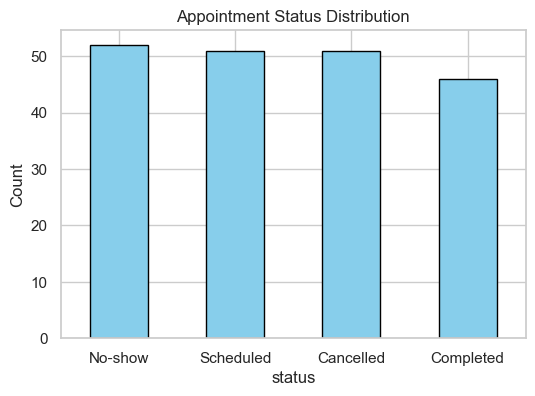

In [27]:
print("--- APPOINTMENTS: INFO ---")
print(appointments.info())

print("\n--- APPOINTMENTS: SHAPE ---")
print(appointments.shape)


# Visualization: Appointment Status Distribution
plt.figure(figsize=(6, 4))
appointments['status'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Appointment Status Distribution')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [28]:
# Convert appointment_date to datetime
appointments['appointment_date'] = pd.to_datetime(appointments['appointment_date'])

# Feature Engineering: Extract time-based features
appointments['appointment_year'] = appointments['appointment_date'].dt.year
appointments['appointment_month'] = appointments['appointment_date'].dt.month
appointments['appointment_dayofweek'] = appointments['appointment_date'].dt.day_name()

print("Appointments Cleaning & Feature Engineering Complete. Sample:")
display(appointments[['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'status']].head())

Appointments Cleaning & Feature Engineering Complete. Sample:


,appointment_id,patient_id,doctor_id,appointment_date,status
0,A001,P034,D009,2023-08-09,Scheduled
1,A002,P032,D004,2023-06-09,No-show
2,A003,P048,D004,2023-06-28,Cancelled
3,A004,P025,D006,2023-09-01,Cancelled
4,A005,P040,D003,2023-07-06,No-show


--- TREATMENTS: INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   treatment_id    200 non-null    object 
 1   appointment_id  200 non-null    object 
 2   treatment_type  200 non-null    object 
 3   description     200 non-null    object 
 4   cost            200 non-null    float64
 5   treatment_date  200 non-null    object 
dtypes: float64(1), object(5)
memory usage: 9.5+ KB
None

--- TREATMENTS: SHAPE ---
(200, 6)


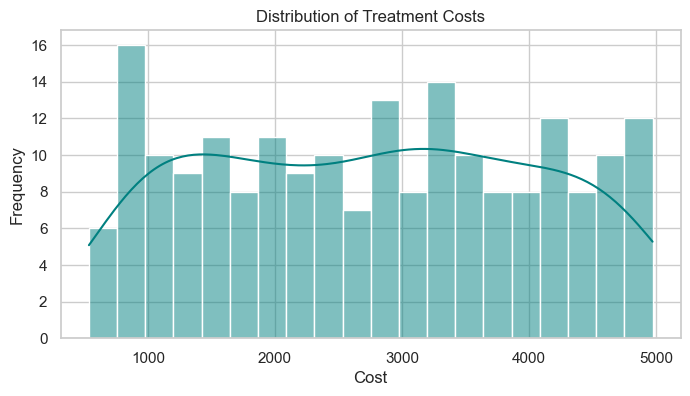

In [29]:
print("--- TREATMENTS: INFO ---")
print(treatments.info())

print("\n--- TREATMENTS: SHAPE ---")
print(treatments.shape)

# Visualization: Distribution of Treatment Costs
plt.figure(figsize=(8, 4))
sns.histplot(treatments['cost'], bins=20, kde=True, color='teal')
plt.title('Distribution of Treatment Costs')
plt.xlabel('Cost')
plt.ylabel('Frequency')
plt.show()


In [30]:
# Convert treatment_date to datetime
treatments['treatment_date'] = pd.to_datetime(treatments['treatment_date'])

# Normalization & Standardization on 'cost'
scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

treatments['cost_standardized'] = scaler.fit_transform(treatments[['cost']])
treatments['cost_normalized'] = minmax_scaler.fit_transform(treatments[['cost']])

print("Treatments Processing Complete. Sample:")
display(treatments[['treatment_id', 'treatment_type', 'cost', 'cost_standardized', 'cost_normalized']].head())

Treatments Processing Complete. Sample:


,treatment_id,treatment_type,cost,cost_standardized,cost_normalized
0,T001,Chemotherapy,3941.97,0.915702,0.767623
1,T002,MRI,4158.44,1.082877,0.816382
2,T003,MRI,3731.55,0.753200,0.720227
3,T004,MRI,4799.86,1.578229,0.960859
4,T005,ECG,582.05,-1.679079,0.010816


--- BILLING: INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   bill_id         200 non-null    object 
 1   patient_id      200 non-null    object 
 2   treatment_id    200 non-null    object 
 3   bill_date       200 non-null    object 
 4   amount          200 non-null    float64
 5   payment_method  200 non-null    object 
 6   payment_status  200 non-null    object 
dtypes: float64(1), object(6)
memory usage: 11.1+ KB
None

--- BILLING: SHAPE ---
(200, 7)


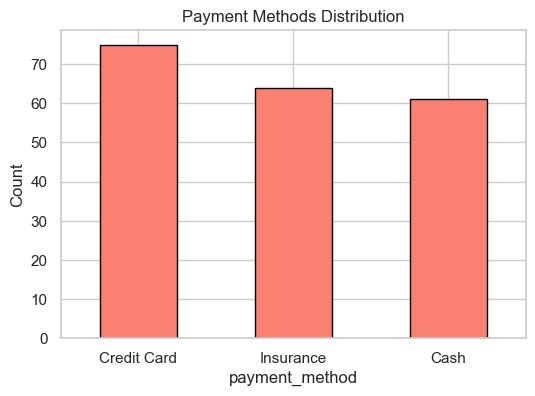

In [31]:
print("--- BILLING: INFO ---")
print(billing.info())

print("\n--- BILLING: SHAPE ---")
print(billing.shape)


# Visualization: Payment Methods Distribution
plt.figure(figsize=(6, 4))
billing['payment_method'].value_counts().plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Payment Methods Distribution')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [32]:
# Convert bill_date to datetime
billing['bill_date'] = pd.to_datetime(billing['bill_date'])

# Feature Engineering: Categorize bills into bins (Low, Medium, High)
billing['amount_category'] = pd.qcut(billing['amount'], q=3, labels=['Low', 'Medium', 'High'])

# Normalization and Standardization on billing 'amount'
billing['amount_standardized'] = scaler.fit_transform(billing[['amount']])
billing['amount_normalized'] = minmax_scaler.fit_transform(billing[['amount']])

print("Billing Processing Complete. Sample:")
display(billing[['bill_id', 'patient_id', 'amount', 'amount_category', 'payment_method', 'payment_status']].head())

Billing Processing Complete. Sample:


,bill_id,patient_id,amount,amount_category,payment_method,payment_status
0,B001,P034,3941.97,High,Insurance,Pending
1,B002,P032,4158.44,High,Insurance,Paid
2,B003,P048,3731.55,High,Insurance,Paid
3,B004,P025,4799.86,High,Insurance,Failed
4,B005,P040,582.05,Low,Credit Card,Pending


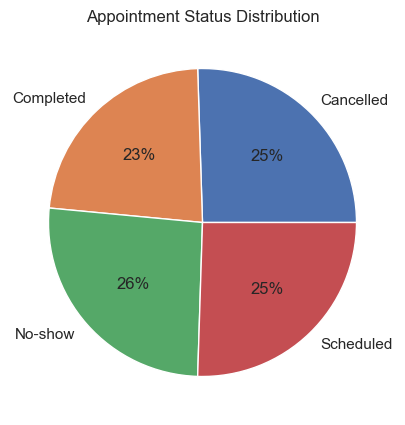

In [33]:
# Pie Chart: Percentage distribution
appointments.groupby('status').size().plot(kind='pie', autopct='%1.0f%%', title='Appointment Status Distribution')
plt.ylabel('')
plt.show()

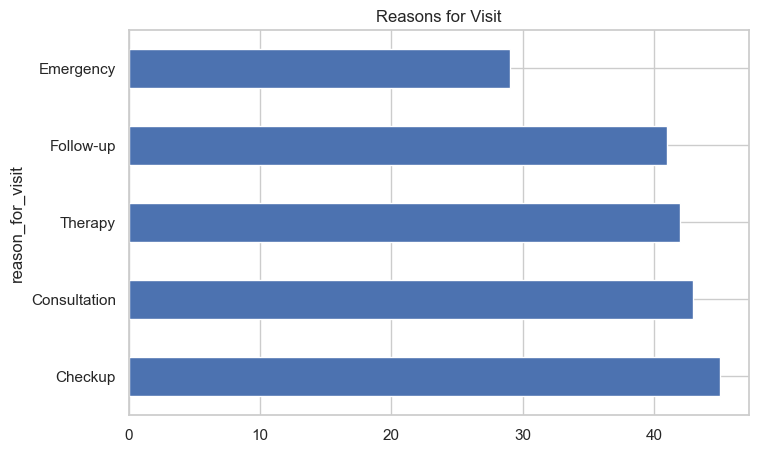

In [34]:
appointments['reason_for_visit'].value_counts().plot(kind='barh', title='Reasons for Visit')
plt.show()

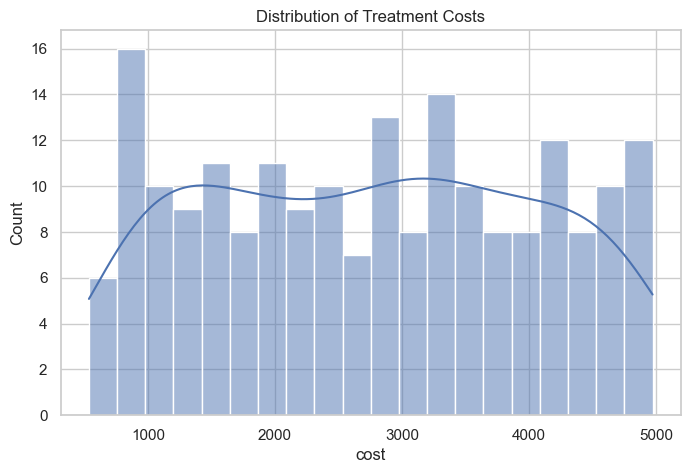

In [35]:
sns.histplot(treatments['cost'], bins=20, kde=True)
plt.title('Distribution of Treatment Costs')
plt.show()

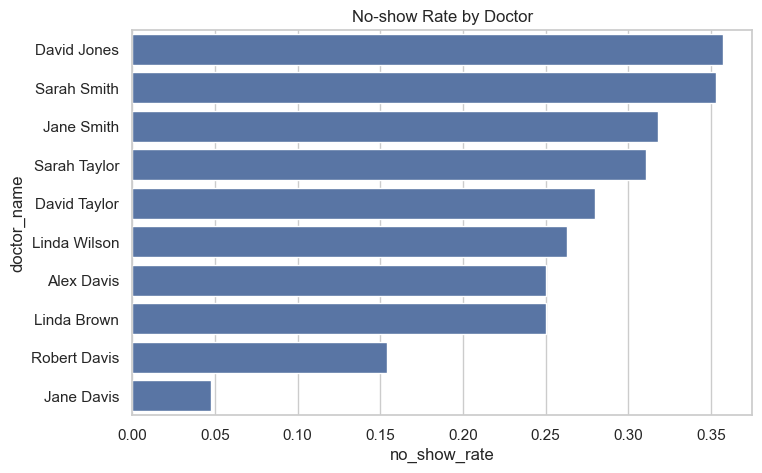

In [36]:
no_show_rate = appointments[appointments['status'] == 'No-show'].groupby('doctor_id').size().reset_index(name='no_shows')
total_appointments = appointments.groupby('doctor_id').size().reset_index(name='total')

no_show_data = no_show_rate.merge(total_appointments, on='doctor_id')
no_show_data['no_show_rate'] = no_show_data['no_shows'] / no_show_data['total']

no_show_data = no_show_data.merge(doctors[['doctor_id','first_name','last_name']], on='doctor_id')
no_show_data['doctor_name'] = no_show_data['first_name'] + ' ' + no_show_data['last_name']
no_show_data = no_show_data.sort_values(by='no_show_rate', ascending=False)

sns.barplot(data=no_show_data, x='no_show_rate', y='doctor_name')
plt.title('No-show Rate by Doctor')
plt.show()

C:\Users\salma\AppData\Local\Temp\ipykernel_10576\1483695167.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=patients, x='insurance_provider', y='age', palette='Set3')


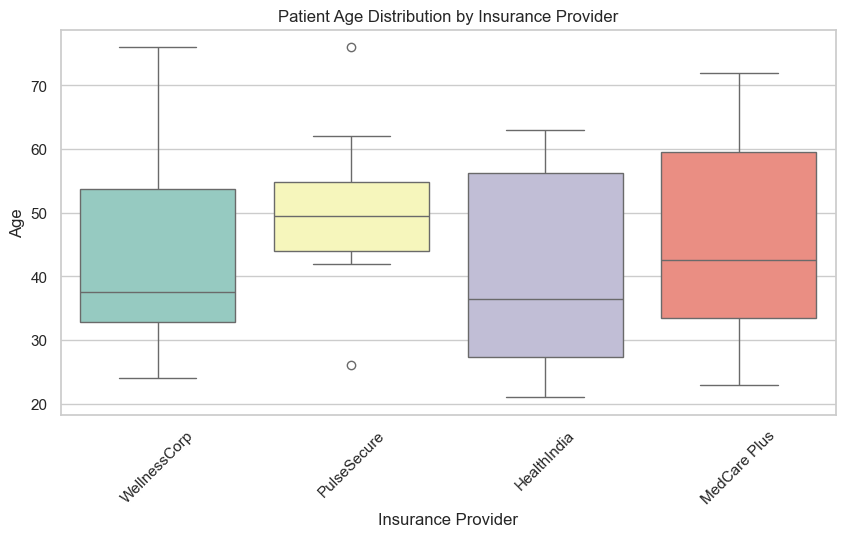

In [37]:
#Question: How does the age distribution of patients vary across different insurance providers?
plt.figure(figsize=(10, 5))
sns.boxplot(data=patients, x='insurance_provider', y='age', palette='Set3')
plt.title('Patient Age Distribution by Insurance Provider')
plt.xlabel('Insurance Provider')
plt.ylabel('Age')
plt.xticks(rotation=45)
plt.show()



C:\Users\salma\AppData\Local\Temp\ipykernel_10576\1555279892.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=doctors, x='hospital_branch', y='years_experience', estimator=np.mean, palette='Blues_d', errorbar=None)


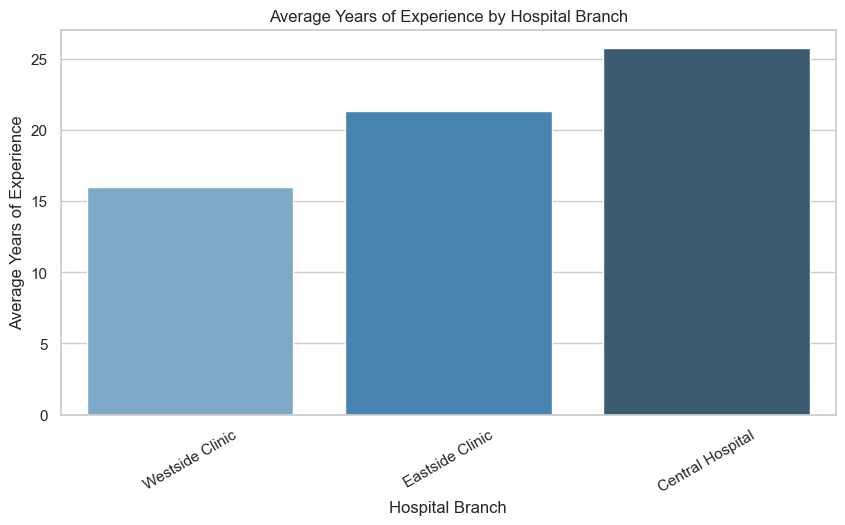

In [38]:
#Question: What is the average years of experience of doctors across different hospital branches?


plt.figure(figsize=(10, 5))
sns.barplot(data=doctors, x='hospital_branch', y='years_experience', estimator=np.mean, palette='Blues_d', errorbar=None)
plt.title('Average Years of Experience by Hospital Branch')
plt.xlabel('Hospital Branch')
plt.ylabel('Average Years of Experience')
plt.xticks(rotation=30)
plt.show()


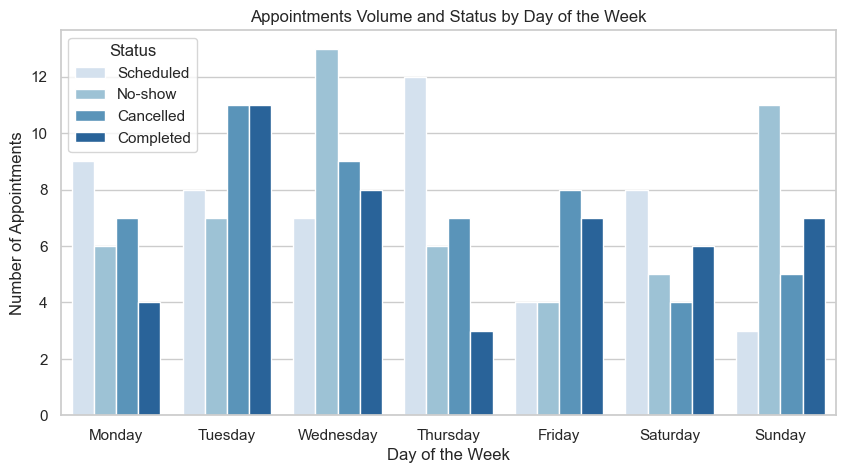

In [39]:
#Question: Which days of the week have the highest appointment volume, and what is their status breakdown?


plt.figure(figsize=(10, 5))
sns.countplot(data=appointments, x='appointment_dayofweek', 
              order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], 
              hue='status', palette='Blues')
plt.title('Appointments Volume and Status by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Appointments')
plt.legend(title='Status')
plt.show()




C:\Users\salma\AppData\Local\Temp\ipykernel_10576\3901720429.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=avg_cost_treatment, x='treatment_type', y='cost', palette='Blues_r')


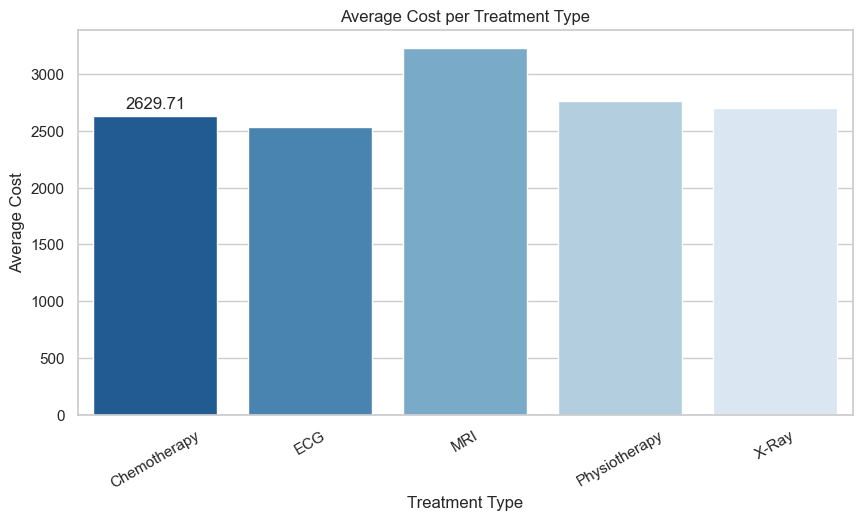

In [ ]:
#Question: Which treatment types incur the highest average cost for patients?


plt.figure(figsize=(10, 5))
avg_cost_treatment = treatments.groupby('treatment_type')['cost'].mean().reset_index()
sns.barplot(data=avg_cost_treatment, x='treatment_type', y='cost', palette='Blues_r')
plt.title('Average Cost per Treatment Type')
plt.xlabel('Treatment Type')
plt.ylabel('Average Cost')
plt.xticks(rotation=30)
plt.show()



C:\Users\salma\AppData\Local\Temp\ipykernel_10576\324142826.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=billing, x='payment_status', y='amount', palette='Pastel1')


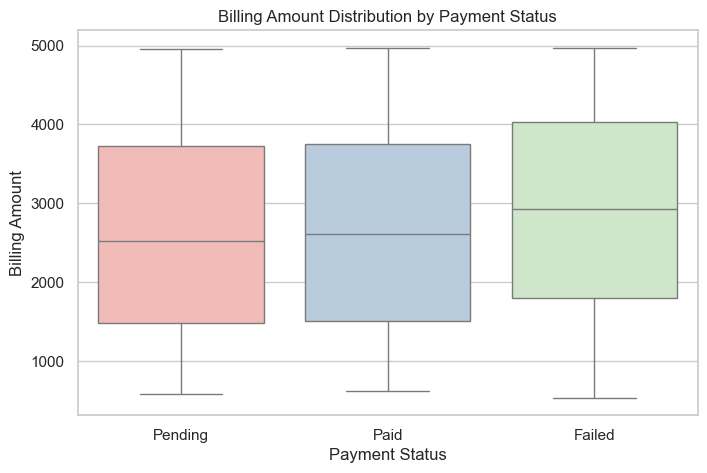

In [41]:
# Question: Is there a significant difference in bill amounts between paid, pending, and failed payment statuses?


plt.figure(figsize=(8, 5))
sns.boxplot(data=billing, x='payment_status', y='amount', palette='Pastel1')
plt.title('Billing Amount Distribution by Payment Status')
plt.xlabel('Payment Status')
plt.ylabel('Billing Amount')
plt.show()
